In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Union, Callable, Optional, Literal
from scipy import sparse as spsp
from scipy.linalg import lu_factor, lu_solve
from numpy.typing import ArrayLike

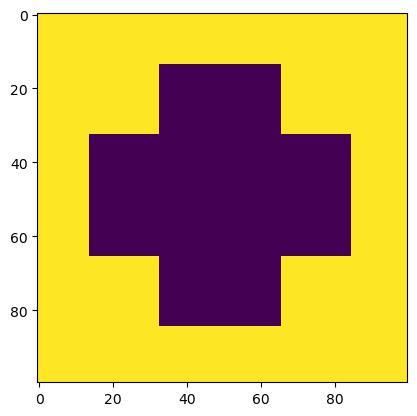

In [2]:
def cross_ic(N):
    base = np.ones([N, N])
    base[N//3:-N//3, N//7:-N//7] = -1
    base[N//7:-N//7, N//3:-N//3] = -1
    return base

plt.imshow(cross_ic(100))

In [3]:
class CH2D:
    def __init__(self,
            a,
            b,
            N_x,
            init_cond,
            phi,
            phi_p,
            eps,
            ):
        self.a = a
        self.b = b
        self.N_x = N_x
        self.dx = (b-a)/(N_x - 1)
        self.init_cond = init_cond

        self.phi = phi
        self.phi_p = phi_p
        self.eps = eps

        self.dt = self.dx**4 * 1000

        self.mu = self.dt / (self.dx**2)

        X, Y = np.meshgrid(np.linspace(a, b, N_x), np.linspace(a, b, N_x))

        C0 = init_cond(X, Y).flatten()
        rng = np.random.default_rng(0)
        C0 = rng.uniform(-1, 1, C0.shape)
        W0 = np.zeros(C0.shape)
        self.Un = np.concat([C0, W0])

        self.A = self._make_A()

    def _make_A(self):
        d0 = -4 * np.ones(self.N)

        dpos1 = np.ones(self.N-1)
        dneg1 = np.ones(self.N-1)

        dposN = np.ones(self.N - self.N_x) # NOTE: Think about this. What happens when N_x != N_y?
        dnegN = np.ones(self.N - self.N_x)

        # Sort out boundary conditions
        dpos1[self.N_x-1::self.N_x] = 0.0
        dneg1[self.N_x-1::self.N_x] = 0.0

        dposN[:self.N_x] *= 2
        dnegN[-self.N_x:] *= 2
        dpos1[::self.N_x] *= 2
        dneg1[-1::-self.N_x] *= 2

        return spsp.diags([dnegN, dneg1, d0, dpos1, dposN], [-self.N_x, -1, 0, 1, self.N_x])

In [4]:
class CahnHilliard2D():
    def __init__(self,
                a_x: float,
                b_x: float,
                N_x: int,
                a_y: float,
                b_y: float,
                N_y: int,
                init_cond: Callable,
                phi: Callable,
                phi_p: Callable,
                phi_pp: Callable,
                eps: float = 0.01,
                dt: Optional[float] = None
                ):
        
        self.a_x = a_x
        self.b_x = b_x
        self.N_x = N_x
        self.dx = (b_x - a_x)/(N_x-1)

        self.a_y = a_y
        self.b_y = b_y
        self.N_y = N_y
        self.dy = (b_y - a_y)/(N_y-1)

        self.N = N_x * N_y

        self.init_cond = init_cond
        self.phi = phi
        self.phi_p = phi_p
        self.phi_pp = phi_pp
        self.eps = eps

        if dt is None:
            self.dt = self.dx**4 * 10000
        else:
            self.dt = dt
        self.mu = self.dt / (self.dx**2)

        self.x_mesh = np.linspace(a_x, b_x, N_x)
        self.y_mesh = np.linspace(a_y, b_y, N_y)

        X, Y = np.meshgrid(self.x_mesh, self.y_mesh)

        C0 = init_cond(X, Y).flatten()
        # C0 = cross_ic(self.N_x).flatten()
        rng = np.random.default_rng(1)
        C0 = rng.uniform(-1, 1, C0.shape)
        W0 = np.zeros(C0.shape)

        self.Un = np.concat([C0, W0])
        self.A = self.construct_A()
        self.mat_base = self._make_mat_base()

        self._make_J_mats()
        self.J = self.compute_J()

        self.M = self.compute_M()

    def construct_A(self):
        d0 = -4 * np.ones(self.N)

        dpos1 = np.ones(self.N-1)
        dneg1 = np.ones(self.N-1)

        dposN = np.ones(self.N - self.N_x) # NOTE: Think about this. What happens when N_x != N_y?
        dnegN = np.ones(self.N - self.N_x)

        # Sort out boundary conditions
        dpos1[self.N_x-1::self.N_x] = 0.0
        dneg1[self.N_x-1::self.N_x] = 0.0

        dposN[:self.N_x] *= 2
        dnegN[-self.N_x:] *= 2
        dpos1[::self.N_x] *= 2
        dneg1[-1::-self.N_x] *= 2

        return spsp.diags([dnegN, dneg1, d0, dpos1, dposN], [-self.N_x, -1, 0, 1, self.N_x])

    def _make_mat_base(self):
        I = spsp.eye(self.N)
        return spsp.block_array([[I, -self.A*self.mu], [self.eps * self.A/(self.dx**2), I]])
    
    def step(self):
        F = lambda x: self.mat_base@x - np.concat([self.Un[:self.N], self.phi_p(x[:self.N])/self.eps])
        J = lambda y: self.mat_base - spsp.diags(self.phi_pp(y[:self.N]), -self.N)/self.eps
        self.Un = self.newton_vec(self.Un, F, J, tol=1e-12, max_iter=20)

    def _make_J_mats(self):
        self._make_d_dx_mat()
        self._make_d_dy_mat()

    def _make_d_dx_mat(self):
        """Construct matrix to compute derivative with respect to x
        """
        dneg1 = -np.ones(self.N - 1)
        d0 = np.zeros(self.N)
        dpos1 = np.ones(self.N - 1)

        # Build in forward and backward differences at the boundary
        dneg1[self.N_x-2::self.N_x] = -2
        dneg1[self.N_x-1::self.N_x] = 0
        d0[::self.N_x] = -2
        d0[self.N_x-1::self.N_x] = 2
        dpos1[::self.N_x] = 2
        dpos1[self.N_x-1::self.N_x] = 0

        self.d_dx = spsp.diags([dneg1, d0, dpos1], [-1, 0, 1]) / (2 * self.dx)

    def _make_d_dy_mat(self):
        """Construct matrix to compute derivative with respect to y
        """
        dneg1 = -np.ones(self.N - self.N_x)
        d0 = np.zeros(self.N )
        dpos1 = np.ones(self.N - self.N_x)

        # Build in forward and backward differences at the boundary
        dneg1[-self.N_x:] = -2
        d0[:self.N_x] = -2
        d0[-self.N_x:] = 2
        dpos1[:self.N_x] = 2

        self.d_dy = spsp.diags([dneg1, d0, dpos1], [-self.N_x, 0, self.N_x]) / (2 * self.dy)
    
    def compute_J(self):
        c = self.Un[:self.N]
        term_1 = 1/self.eps * self.phi(c)
        term_2 = self.eps * ((self.d_dx@c)**2  + (self.d_dy@c)**2)/ 2
        return (term_1 + term_2).sum() * self.dx * self.dy
    
    def compute_M(self):
        c = np.reshape(self.Un[:self.N], [self.N_x, self.N_y])

        s = c[:-1][:-1].sum() + c[:-1][1:].sum() + c[1:][:-1].sum() + c[1:][1:].sum()
        return self.dx * self.dy * s / 4
    
# class CHSchemeB(CahnHilliard2D):
#     def __init__(self, *args, **kwargs):
#         super().__init__(*args, **kwargs)
#         self.compute_lu()

#     def step(self):
#         F = lambda x: self.mat_base@x - np.concat([self.Un[:self.N], self.phi_p(x[:self.N], self.Un[:self.N])/self.eps])
#         self.Un = self.lu_newton(self.Un, F, tol=1e-12, max_iter=20)

#     def compute_lu(self):
#         J = self.mat_base - spsp.diags(2*np.ones(self.N), -self.N)/self.eps
#         self.lu = spsp.linalg.splu(J.tocsc())

#     def lu_newton(self,
#         xk: Union[float, int],
#         F: Callable,
#         tol: float = 1e-13,
#         max_iter: int = 100,
#         ) -> float:
#         k = 0
#         while (abs(F(xk)).sum() > tol) and (k < max_iter):
#             xk = xk + self.lu.solve(-F(xk))
#             k += 1
#         return xk
    
class CHSchemeB(CahnHilliard2D):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.compute_lu()

    def _make_mat_base(self):
        I = spsp.eye(self.N)
        return spsp.block_array([[I, -self.A*self.mu], [self.eps * self.A/(self.dx**2) - 2*I/self.eps, I]])
    
    def compute_lu(self):
        self.lu, self.piv = lu_factor(self.mat_base.todense())

    def step(self):
        Cn = self.Un[:self.N]
        b2 = (Cn**3-3*Cn) / self.eps
        b = np.concat([Cn, b2])
        
        self.Un = lu_solve((self.lu, self.piv), b)

    @staticmethod
    def neumann_1d(n):
        """
        1D second-difference matrix with Neumann BC on both ends
        (matrix size n x n).
        Interior: [-1, 2, -1]; Neumann is implemented by doubling the off-diagonals
        adjacent to boundaries so the row sum is zero.
        """
        if n == 1:
            return spsp.csr_matrix([[0.0]])   # trivial 1x1 Laplacian (Neumann)
        main =  -2.0 * np.ones(n)
        off_l  =   1.0 * np.ones(n-1)
        off_r = 1.0 * np.ones(n-1)
        # For Neumann: reflect missing neighbour -> double the adjacent off-diagonals
        off_l[-1] *= 2.0     # left boundary: double the (0,1) link
        off_r[0] *= 2.0    # right boundary: double the (n-1,n-2) link
        T = spsp.diags([off_l, main, off_r], offsets=[-1,0,1], format='csr')
        return T

    def construct_A(self):
        Tx = self.neumann_1d(self.N_x)
        Ty = self.neumann_1d(self.N_y)
        I_x = spsp.eye(self.N_x, format='csr')
        I_y = spsp.eye(self.N_y, format='csr')
        A = spsp.kron(I_y, Tx, format='csr') + spsp.kron(Ty, I_x, format='csr')
        return A

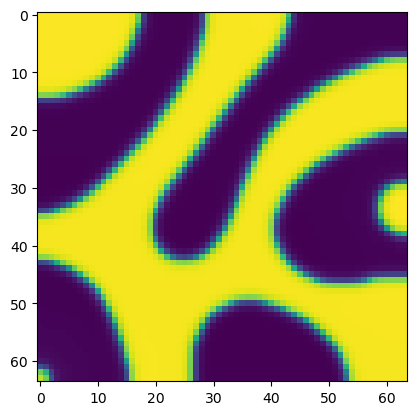

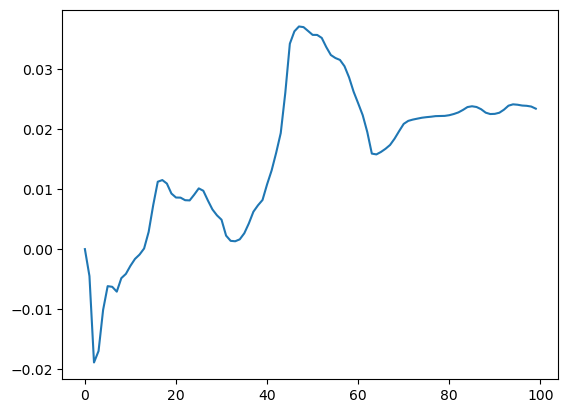

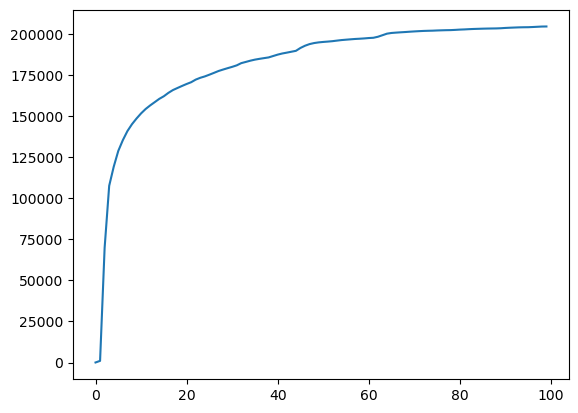

In [6]:
class CHB:
    def __init__(self, a, b, N_x, epsilon=0.01):
        self.a = a
        self.b = b
        self.N_x = N_x
        self.N = N_x**2

        self.dx = (b - a) / (N_x - 1)
        self.dt = self.dx ** 4 * 100
        self.mu = self.dt / (self.dx**2)

        self.epsilon = epsilon
        self.phi = lambda x: (1 - x**2) ** 2 / 4

        self.A = self._make_A()
        self.lu, self.piv = self._make_lu()

        self._make_d_dx_mat()
        self._make_d_dy_mat()

        rng = np.random.default_rng()
        C0 = rng.uniform(-1, 1, N_x**2)
        W0 = np.zeros(C0.shape)
        self.Un = np.concat([C0, W0])

        self.M0 = self.compute_M()

    @staticmethod
    def neumann_1d(n):
        """
        1D second-difference matrix with Neumann BC on both ends
        (matrix size n x n).
        Interior: [-1, 2, -1]; Neumann is implemented by doubling the off-diagonals
        adjacent to boundaries so the row sum is zero.
        """
        if n == 1:
            return spsp.csr_matrix([[0.0]])   # trivial 1x1 Laplacian (Neumann)
        main =  -2.0 * np.ones(n)
        off_l  =   1.0 * np.ones(n-1)
        off_r = 1.0 * np.ones(n-1)
        # For Neumann: reflect missing neighbour -> double the adjacent off-diagonals
        off_l[-1] *= 2.0     # left boundary: double the (0,1) link
        off_r[0] *= 2.0    # right boundary: double the (n-1,n-2) link
        T = spsp.diags([off_l, main, off_r], offsets=[-1,0,1], format='csr')
        return T
    
    def _make_A(self):
        Tx = self.neumann_1d(self.N_x)
        Ty = self.neumann_1d(self.N_x)
        I_x = spsp.eye(self.N_x, format='csr')
        I_y = spsp.eye(self.N_x, format='csr')
        return spsp.kron(I_y, Tx, format='csr') + spsp.kron(Ty, I_x, format='csr')
    
    def _make_lu(self):
        b1 = spsp.eye(self.N, self.N, format='csr')
        b2 = -self.A / self.dx**2
        b3 = self.epsilon * self.A / (self.dx**2) - 2 * b1 / self.epsilon

        mat = spsp.block_array([[b1 / self.dt, b2], [b3, b1]], format='csr')
        return lu_factor(mat.todense())

    def step(self):
        Cn = self.Un[:self.N]
        Wn = self.Un[self.N:]

        b2 = (Cn **3 - 3 * Cn / self.epsilon)

        b = np.concat([Cn /self.dt, b2])
        self.Un = lu_solve((self.lu, self.piv), b)

    def compute_M(self):
        c = np.reshape(self.Un[:self.N], [self.N_x, self.N_x])

        s = c[:-1][:-1].sum() + c[:-1][1:].sum() + c[1:][:-1].sum() + c[1:][1:].sum()
        return self.dx ** 2 * s / 4
    
    def _make_d_dx_mat(self):
        """Construct matrix to compute derivative with respect to x
        """
        dneg1 = -np.ones(self.N - 1)
        d0 = np.zeros(self.N)
        dpos1 = np.ones(self.N - 1)

        # Build in forward and backward differences at the boundary
        dneg1[self.N_x-2::self.N_x] = -2
        dneg1[self.N_x-1::self.N_x] = 0
        d0[::self.N_x] = -2
        d0[self.N_x-1::self.N_x] = 2
        dpos1[::self.N_x] = 2
        dpos1[self.N_x-1::self.N_x] = 0

        self.d_dx = spsp.diags([dneg1, d0, dpos1], [-1, 0, 1]) / (2 * self.dx)

    def _make_d_dy_mat(self):
        """Construct matrix to compute derivative with respect to y
        """
        dneg1 = -np.ones(self.N - self.N_x)
        d0 = np.zeros(self.N )
        dpos1 = np.ones(self.N - self.N_x)

        # Build in forward and backward differences at the boundary
        dneg1[-self.N_x:] = -2
        d0[:self.N_x] = -2
        d0[-self.N_x:] = 2
        dpos1[:self.N_x] = 2

        self.d_dy = spsp.diags([dneg1, d0, dpos1], [-self.N_x, 0, self.N_x]) / (2 * self.dx)

    def compute_J(self):
        c = self.Un[:self.N]
        term_1 = self.phi(c) / self.epsilon
        term_2 = self.epsilon * ((self.d_dx@c)**2  + (self.d_dy@c)**2)/ 2
        return (term_1 + term_2).sum() * self.dx * self.dx


N = 64
n_steps = 1000
sample_every = 10
solver = CHB(0, 1, N)
vals = []
J_vals = []
M_vals = []
M0 = solver.M0
for i in range(n_steps):
    solver.step()
    if i % sample_every == 0:
        vals.append(np.reshape(solver.Un[:N**2], [N, N]))
        M_vals.append(solver.compute_M() - M0)
        J_vals.append(solver.compute_J())

plt.imshow(np.reshape(solver.Un[:N**2], [N, N]))
plt.show()
plt.plot(M_vals)
plt.show()
plt.plot(J_vals)
plt.show()

In [6]:
def neumann_1d(n):
    """
    1D second-difference matrix with Neumann BC on both ends
    (matrix size n x n).
    Interior: [-1, 2, -1]; Neumann is implemented by doubling the off-diagonals
    adjacent to boundaries so the row sum is zero.
    """
    if n == 1:
        return spsp.csr_matrix([[0.0]])   # trivial 1x1 Laplacian (Neumann)
    main =  -2.0 * np.ones(n)
    off_l  =   1.0 * np.ones(n-1)
    off_r = 1.0 * np.ones(n-1)
    # For Neumann: reflect missing neighbour -> double the adjacent off-diagonals
    off_l[-1] *= 2.0     # left boundary: double the (0,1) link
    off_r[0] *= 2.0    # right boundary: double the (n-1,n-2) link
    T = spsp.diags([off_l, main, off_r], offsets=[-1,0,1], format='csr')
    return T

def construct_A(N_x, N_y):
    Tx = neumann_1d(N_x)
    Ty = neumann_1d(N_y)
    I_x = spsp.eye(N_x, format='csr')
    I_y = spsp.eye(N_y, format='csr')
    A = spsp.kron(I_y, Tx, format='csr') + spsp.kron(Ty, I_x, format='csr')
    return A

construct_A(3, 3).todense()

matrix([[-4.,  2.,  0.,  2.,  0.,  0.,  0.,  0.,  0.],
        [ 1., -4.,  1.,  0.,  2.,  0.,  0.,  0.,  0.],
        [ 0.,  2., -4.,  0.,  0.,  2.,  0.,  0.,  0.],
        [ 1.,  0.,  0., -4.,  2.,  0.,  1.,  0.,  0.],
        [ 0.,  1.,  0.,  1., -4.,  1.,  0.,  1.,  0.],
        [ 0.,  0.,  1.,  0.,  2., -4.,  0.,  0.,  1.],
        [ 0.,  0.,  0.,  2.,  0.,  0., -4.,  2.,  0.],
        [ 0.,  0.,  0.,  0.,  2.,  0.,  1., -4.,  1.],
        [ 0.,  0.,  0.,  0.,  0.,  2.,  0.,  2., -4.]])

In [8]:
test = CahnHilliard2D(0, 1, 3, 0, 1, 3, lambda x, y: np.ones(x.shape) + np.ones(y.shape), lambda x: 1, None, None)

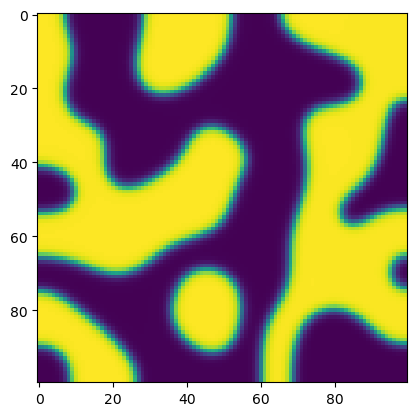

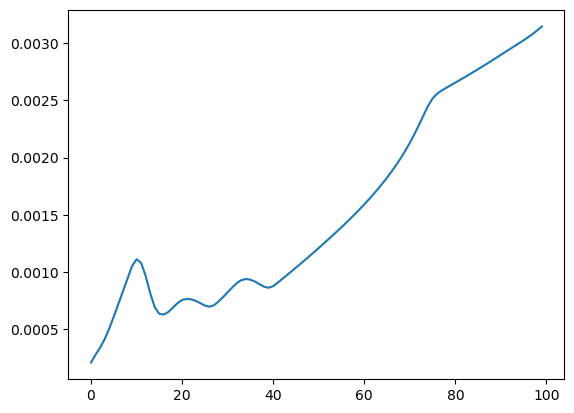

In [7]:
N = 100
n_steps = 100
sample_every = 10

phi = lambda x: (1-x**2)**2/4
phi_p = lambda x, y: 2*x+y**3-3*y
phi_pp = None
solver = CHSchemeB(0, 1, N, 0, 1, N, lambda x, y: np.cos(np.pi * x) * np.cos(np.pi * y), phi, phi_p, phi_pp, eps=0.01)
vals = []
J_vals = []
M_vals = []
M0 = solver.M
for i in range(n_steps):
    solver.step()
    if i % sample_every == 0:
        vals.append(np.reshape(solver.Un[:N**2], [N, N]))
    J_vals.append(solver.compute_J())
    M_vals.append(solver.compute_M()-M0)


plt.imshow(np.reshape(solver.Un[:N**2], [N, N]))
plt.show()
plt.plot(M_vals)
plt.show()

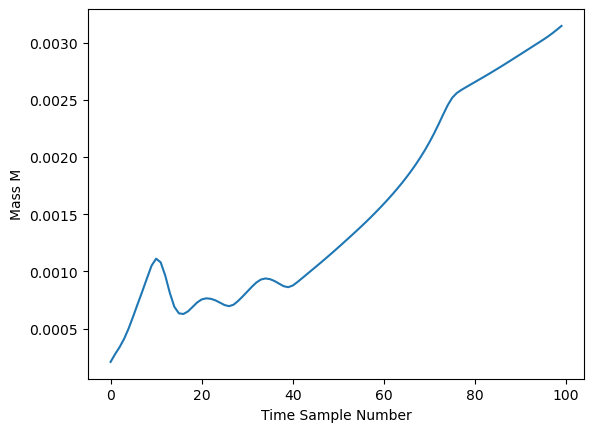

[Text(0.5, 0, 'Time Sample Number'), Text(0, 0.5, 'Energy J')]

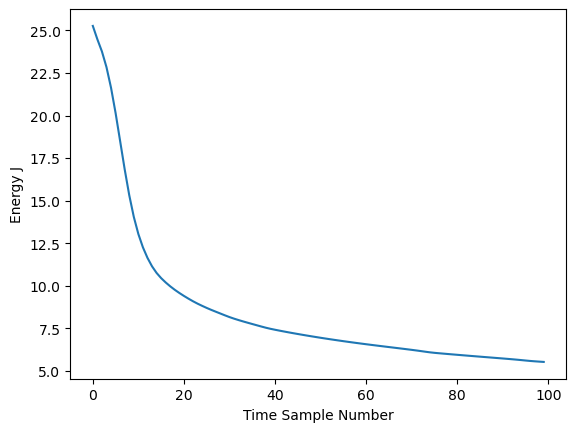

In [16]:
plt.plot(M_vals)
plt.gca().set(
    xlabel='Time Sample Number',
    ylabel='Mass M'
)
plt.show()
plt.plot(J_vals)
plt.gca().set(
    xlabel='Time Sample Number',
    ylabel='Energy J'
)

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

def animate_with_matplotlib(meshes, out_path="mesh_anim.gif", fps=10, cmap="viridis"):
    vmin = min(m.min() for m in meshes)
    vmax = max(m.max() for m in meshes)

    fig, ax = plt.subplots()
    im = ax.imshow(meshes[0], vmin=vmin, vmax=vmax, cmap=cmap, animated=True)
    cb = fig.colorbar(im, ax=ax)
    ax.set_title("Frame 0")

    def update(i):
        im.set_data(meshes[i])
        ax.set_title(f"Frame {i}")
        return (im,)

    anim = FuncAnimation(fig, update, frames=len(meshes), interval=1000/fps, blit=True)
    # Save as GIF using PillowWriter:
    writer = PillowWriter(fps=fps)
    anim.save(out_path, writer=writer)
    plt.close(fig)
    print(f"Saved GIF: {out_path}")

# animate_with_matplotlib(vals, out_path="cahn_hilliard_2d_v5.gif")

Saved GIF: cahn_hilliard_2d_v4.gif
